# Obtain
Obtain the challenge data set and the weather data

In [ ]:
import pandas as pd

df = pd.read_csv("Training_data_uhi_index_2025-02-18.csv")

In [ ]:
display(df)

,Longitude,Latitude,datetime,UHI Index
0,-73.909167,40.813107,24-07-2021 15:53,1.030289
1,-73.909187,40.813045,24-07-2021 15:53,1.030289
2,-73.909215,40.812978,24-07-2021 15:53,1.023798
3,-73.909242,40.812908,24-07-2021 15:53,1.023798
4,-73.909257,40.812845,24-07-2021 15:53,1.021634
...,...,...,...,...
11224,-73.957050,40.790333,24-07-2021 15:57,0.972470
11225,-73.957063,40.790308,24-07-2021 15:57,0.972470
11226,-73.957093,40.790270,24-07-2021 15:57,0.981124
11227,-73.957112,40.790253,24-07-2021 15:59,0.981245


In [ ]:
df.shape

(11229, 4)

# Scrub

In [ ]:
# prompt: order by datetime

import pandas as pd
df['datetime'] = pd.to_datetime(df['datetime'])
df = df.sort_values(by='datetime')
display(df)


<ipython-input-41-ffb8c02f02f3>:4: UserWarning: Parsing dates in %d-%m-%Y %H:%M format when dayfirst=False (the default) was specified. Pass `dayfirst=True` or specify a format to silence this warning.
  df['datetime'] = pd.to_datetime(df['datetime'])


,Longitude,Latitude,datetime,UHI Index
1745,-73.977157,40.771555,2021-07-24 15:01:00,0.975234
243,-73.910167,40.803775,2021-07-24 15:01:00,1.000718
244,-73.910268,40.803817,2021-07-24 15:01:00,1.000718
1735,-73.978742,40.771675,2021-07-24 15:01:00,0.975234
1737,-73.978453,40.771677,2021-07-24 15:01:00,0.970907
...,...,...,...,...
1730,-73.979060,40.771682,2021-07-24 15:59:00,0.975234
1731,-73.979027,40.771695,2021-07-24 15:59:00,0.975234
1732,-73.978947,40.771705,2021-07-24 15:59:00,0.975234
3314,-73.905072,40.844538,2021-07-24 15:59:00,1.000838


In [ ]:
# prompt: generate a feature called minute which represents the minute portion of the datetime

df['minute'] = df['datetime'].dt.minute


# Explore

In [ ]:
min(df.datetime), max(df.datetime)

(Timestamp('2021-07-24 15:01:00'), Timestamp('2021-07-24 15:59:00'))

In [ ]:
import pandas as pd
from datetime import datetime

def analyze_datetime_granularity_df(df, datetime_col='datetime'):
    """
    Analyze the granularity of datetime values in a DataFrame

    Parameters:
    df: pandas DataFrame
    datetime_col: name of the datetime column (default='datetime')
    """
    # Ensure datetime column is datetime type
    if not pd.api.types.is_datetime64_any_dtype(df[datetime_col]):
        df[datetime_col] = pd.to_datetime(df[datetime_col])

    # Analyze time differences
    time_diffs = df[datetime_col].diff().dropna()

    analysis = {
        'min_difference': time_diffs.min(),
        'max_difference': time_diffs.max(),
        'unique_times': df[datetime_col].nunique(),
        'total_records': len(df),
        'has_seconds': any('S' in str(diff) for diff in time_diffs),
        'has_milliseconds': any('ms' in str(diff) for diff in time_diffs),
        'time_range': df[datetime_col].max() - df[datetime_col].min(),
        'sample_values': df[datetime_col].head().tolist()
    }

    return analysis

def format_time_analysis(analysis):
    """
    Format the analysis results into a readable string
    """
    return f"""Datetime Granularity Analysis:

- Smallest time difference: {analysis['min_difference']}
- Largest time difference: {analysis['max_difference']}
- Number of unique timestamps: {analysis['unique_times']}
- Total records: {analysis['total_records']}
- Contains seconds: {analysis['has_seconds']}
- Contains milliseconds: {analysis['has_milliseconds']}
- Total time range: {analysis['time_range']}
- Sample values: {[str(x) for x in analysis['sample_values']]}"""

# If your datetime column is named 'datetime':
results = analyze_datetime_granularity_df(df)

# Or if your datetime column has a different name:
results = analyze_datetime_granularity_df(df, datetime_col='datetime')

# Print the formatted results
print(format_time_analysis(results))

Datetime Granularity Analysis:

- Smallest time difference: 0 days 00:00:00
- Largest time difference: 0 days 00:01:00
- Number of unique timestamps: 59
- Total records: 11229
- Contains seconds: False
- Contains milliseconds: False
- Total time range: 0 days 00:58:00
- Sample values: ['2021-07-24 15:01:00', '2021-07-24 15:01:00', '2021-07-24 15:01:00', '2021-07-24 15:01:00', '2021-07-24 15:01:00']


In [ ]:
# prompt: group by longitude latitude for count of rows, order by count

import pandas as pd

# Assuming your DataFrame is named 'df'
grouped = df.groupby(['Longitude', 'Latitude']).size().reset_index(name='counts')
ordered_grouped = grouped.sort_values('counts', ascending=False)
ordered_grouped


,Longitude,Latitude,counts
0,-73.994457,40.771468,1
7490,-73.916647,40.818755,1
7482,-73.916707,40.816543,1
7483,-73.916702,40.815750,1
7484,-73.916692,40.811897,1
...,...,...,...
3744,-73.951927,40.787617,1
3745,-73.951910,40.769373,1
3746,-73.951910,40.803873,1
3747,-73.951905,40.811565,1


^ This confirms that each longitude and latitude occurs only once.

In [ ]:
# prompt: # prompt: # prompt: group by date time get count
# # import pandas as pd
# # # Assuming your DataFrame is named 'df' and 'datetime' column exists
# # # and is already in datetime format as per your previous code.
# # # Group by date and get the count
# # df['date'] = df['datetime'].dt.date  # Extract the date part
# # date_counts = df.groupby('date').size().reset_index(name='count')
# # date_counts
# # group by date time
# # Group by datetime and get the count
# datetime_counts = df.groupby('datetime').size().reset_index(name='count')
# datetime_counts
# Get count, average Longitude, average Latitude, average UHI Index and median UHI Index

import pandas as pd

# Assuming your DataFrame is named 'df' and 'datetime' column exists
# and is already in datetime format.

# Group by datetime and get the count, along with other aggregated values
datetime_stats = df.groupby('datetime').agg(
    count=('UHI Index', 'count'),
    mean_longitude=('Longitude', 'mean'),
    mean_latitude=('Latitude', 'mean'),
    mean_uhi=('UHI Index', 'mean'),
    median_uhi=('UHI Index', 'median')
).reset_index()

datetime_stats


,datetime,count,mean_longitude,mean_latitude,mean_uhi,median_uhi
0,2021-07-24 15:01:00,46,-73.934492,40.791550,0.990035,0.996391
1,2021-07-24 15:02:00,66,-73.945649,40.785430,1.000132,0.985091
2,2021-07-24 15:03:00,37,-73.922788,40.799716,1.021004,1.026923
3,2021-07-24 15:04:00,123,-73.939674,40.790160,0.998338,0.998795
4,2021-07-24 15:05:00,41,-73.952075,40.781049,1.000146,0.990861
5,2021-07-24 15:06:00,80,-73.942730,40.789339,1.002424,1.005526
6,2021-07-24 15:07:00,123,-73.934738,40.801951,1.011307,1.008411
7,2021-07-24 15:08:00,154,-73.944532,40.793458,1.005668,1.008171
8,2021-07-24 15:09:00,153,-73.921633,40.809058,0.993553,0.993506
9,2021-07-24 15:10:00,122,-73.943267,40.790435,0.992803,0.989058


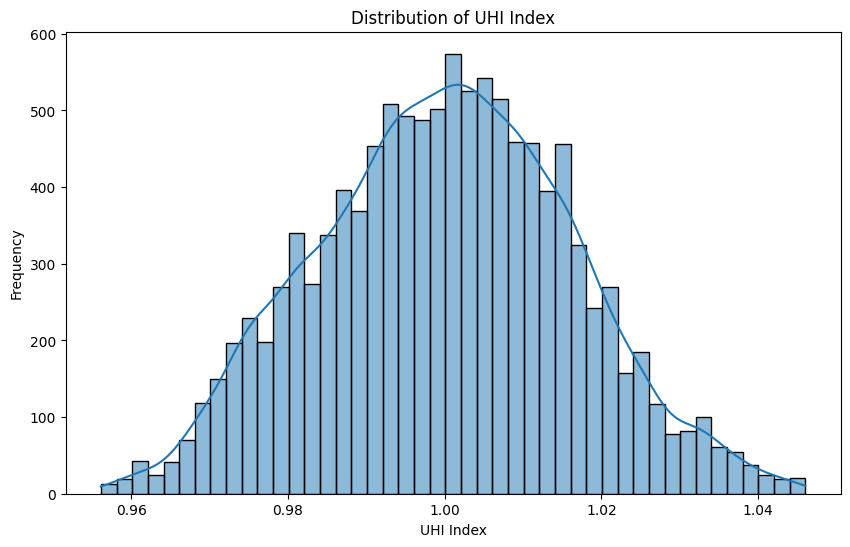

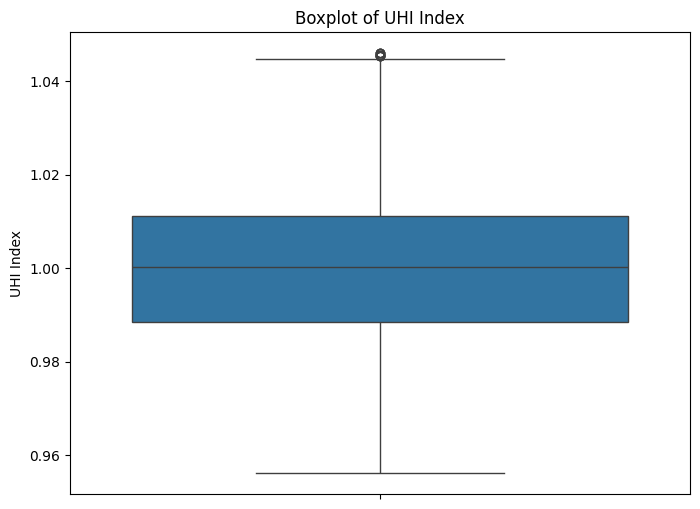

In [ ]:
# prompt: Distribution of UHI Index

import matplotlib.pyplot as plt
import seaborn as sns

# Assuming 'uhi_index' is the column containing the UHI index values
plt.figure(figsize=(10, 6))
sns.histplot(df['UHI Index'], kde=True)  # kde=True adds a kernel density estimate
plt.title('Distribution of UHI Index')
plt.xlabel('UHI Index')
plt.ylabel('Frequency')
plt.show()


# Boxplot
plt.figure(figsize=(8, 6))
sns.boxplot(y=df['UHI Index'])
plt.title('Boxplot of UHI Index')
plt.ylabel('UHI Index')
plt.show()


In [ ]:
# prompt: examine outliers by iqr method

import pandas as pd

# Calculate Q1, Q3, and IQR
Q1 = df['UHI Index'].quantile(0.25)
Q3 = df['UHI Index'].quantile(0.75)
IQR = Q3 - Q1

# Define bounds for outliers
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

# Identify outliers
outliers = df[(df['UHI Index'] < lower_bound) | (df['UHI Index'] > upper_bound)]

# Print or display outliers
print("Outliers (IQR Method):")
outliers

# You can also visualize the outliers using a boxplot (already shown in previous code)
# or by creating a scatter plot highlighting outliers


Outliers (IQR Method):


,Longitude,Latitude,datetime,UHI Index,minute
975,-73.917762,40.815135,2021-07-24 15:28:00,1.045555,28
9755,-73.933748,40.854302,2021-07-24 15:32:00,1.045435,32
9753,-73.933613,40.854578,2021-07-24 15:32:00,1.045435,32
9754,-73.933737,40.854323,2021-07-24 15:32:00,1.045435,32
9982,-73.951860,40.827212,2021-07-24 15:32:00,1.046036,32
9983,-73.951802,40.827192,2021-07-24 15:32:00,1.046036,32
9984,-73.951723,40.827168,2021-07-24 15:32:00,1.046036,32
9985,-73.951642,40.827142,2021-07-24 15:32:00,1.046036,32
9752,-73.933585,40.854660,2021-07-24 15:32:00,1.045435,32
4158,-73.914647,40.818320,2021-07-24 15:45:00,1.045675,45


In [ ]:
# prompt: remove outliers

# Remove outliers
df_no_outliers = df[(df['UHI Index'] >= lower_bound) & (df['UHI Index'] <= upper_bound)]

# Print or display the DataFrame without outliers
print("DataFrame without outliers:")
df_no_outliers


DataFrame without outliers:


,Longitude,Latitude,datetime,UHI Index,minute
1745,-73.977157,40.771555,2021-07-24 15:01:00,0.975234,1
243,-73.910167,40.803775,2021-07-24 15:01:00,1.000718,1
244,-73.910268,40.803817,2021-07-24 15:01:00,1.000718,1
1735,-73.978742,40.771675,2021-07-24 15:01:00,0.975234,1
1737,-73.978453,40.771677,2021-07-24 15:01:00,0.970907,1
...,...,...,...,...,...
1730,-73.979060,40.771682,2021-07-24 15:59:00,0.975234,59
1731,-73.979027,40.771695,2021-07-24 15:59:00,0.975234,59
1732,-73.978947,40.771705,2021-07-24 15:59:00,0.975234,59
3314,-73.905072,40.844538,2021-07-24 15:59:00,1.000838,59


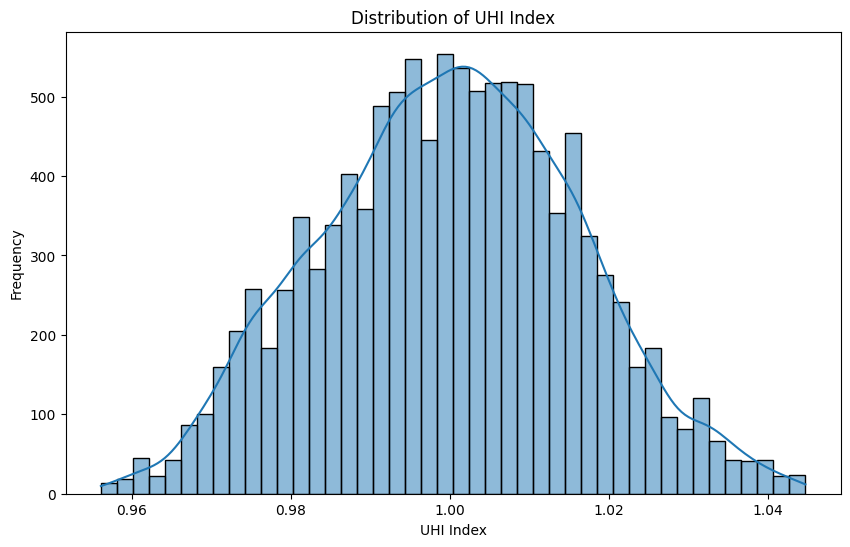

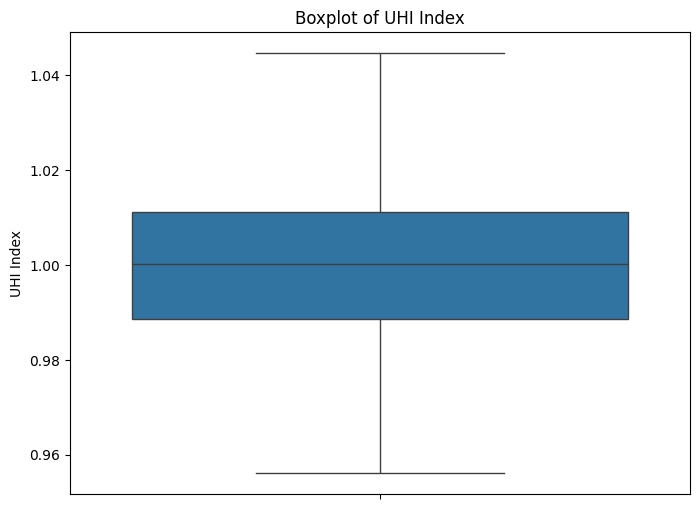

In [ ]:
# prompt: Distribution of UHI Index

import matplotlib.pyplot as plt
import seaborn as sns

# Assuming 'uhi_index' is the column containing the UHI index values
plt.figure(figsize=(10, 6))
sns.histplot(df_no_outliers['UHI Index'], kde=True)  # kde=True adds a kernel density estimate
plt.title('Distribution of UHI Index')
plt.xlabel('UHI Index')
plt.ylabel('Frequency')
plt.show()


# Boxplot
plt.figure(figsize=(8, 6))
sns.boxplot(y=df_no_outliers['UHI Index'])
plt.title('Boxplot of UHI Index')
plt.ylabel('UHI Index')
plt.show()


In [ ]:
# prompt: group Longitude Latitude aggregate average UHI Index

import pandas as pd

# Assuming 'df_no_outliers' is your DataFrame without outliers
# Group by 'Longitude' and 'Latitude' and calculate the average 'UHI Index'
grouped_df = df_no_outliers.groupby(['Longitude', 'Latitude'])['UHI Index'].mean().reset_index()

# Display the grouped DataFrame
display(grouped_df)


,Longitude,Latitude,UHI Index
0,-73.994457,40.771468,1.017186
1,-73.994443,40.771493,1.015023
2,-73.994430,40.771518,1.015023
3,-73.994415,40.771545,1.017186
4,-73.994400,40.771577,1.017186
...,...,...,...
11213,-73.879467,40.805903,0.988337
11214,-73.879462,40.805860,0.988337
11215,-73.879460,40.805783,0.996992
11216,-73.879458,40.805800,0.999155


In [ ]:
df.shape[0] - grouped_df.shape[0]

11

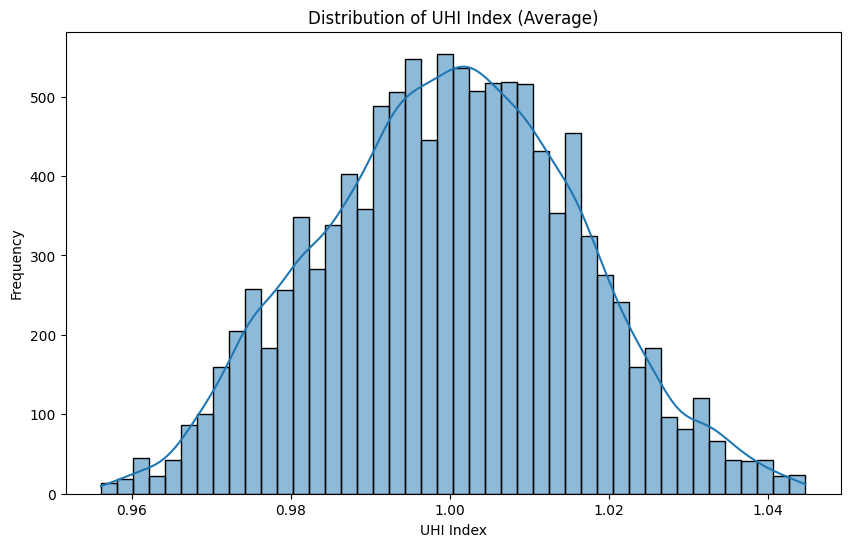

In [ ]:
# prompt: plot distribution of UHI Index again

# Assuming 'df_no_outliers' is your DataFrame without outliers from the previous code

import matplotlib.pyplot as plt
import seaborn as sns

# Assuming 'uhi_index' is the column containing the UHI index values
plt.figure(figsize=(10, 6))
sns.histplot(grouped_df['UHI Index'], kde=True)  # kde=True adds a kernel density estimate
plt.title('Distribution of UHI Index (Average)')
plt.xlabel('UHI Index')
plt.ylabel('Frequency')
plt.show()


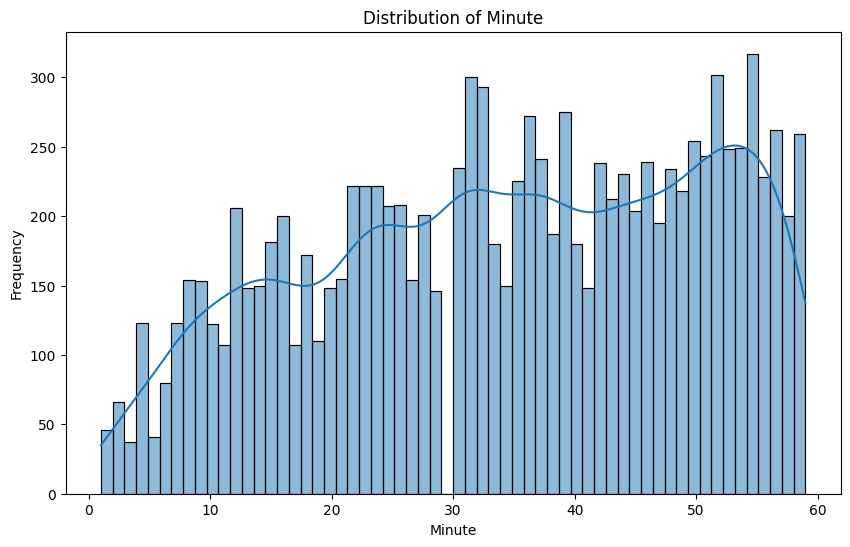

In [ ]:
# prompt: distribution of minute

import matplotlib.pyplot as plt
import seaborn as sns

# Assuming 'df' is your DataFrame and 'minute' column exists

plt.figure(figsize=(10, 6))
sns.histplot(df['minute'], kde=True, bins=60)  # Use bins=60 for minutes
plt.title('Distribution of Minute')
plt.xlabel('Minute')
plt.ylabel('Frequency')
plt.show()


# Model

In [ ]:
# prompt: cross fold validation of linear regression, ridge regression, lasso regression, elastic net, naive bayes regression, decision tree, random forest, light gbm, xgboost, svr, and knn regression and report the results sorted in descending order of R2 score.

import pandas as pd
from sklearn.model_selection import KFold, cross_val_score
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from lightgbm import LGBMRegressor
from xgboost import XGBRegressor
from sklearn.svm import SVR
from sklearn.neighbors import KNeighborsRegressor
import numpy as np

# Assuming 'grouped_df' is your preprocessed DataFrame
# Replace 'UHI Index' with the actual target variable column name if different
X = grouped_df.drop('UHI Index', axis=1)
y = grouped_df['UHI Index']

# Create a dictionary of models
models = {
    'Linear Regression': LinearRegression(),
    'Ridge Regression': Ridge(),
    'Lasso Regression': Lasso(),
    'Elastic Net': ElasticNet(),
    'Naive Bayes Regression': GaussianNB(),  # Note: Naive Bayes is a classification algorithm, use with caution for regression
    'Decision Tree': DecisionTreeRegressor(),
    'Random Forest': RandomForestRegressor(),
    'LightGBM': LGBMRegressor(),
    'XGBoost': XGBRegressor(),
    'SVR': SVR(),
    'KNN Regression': KNeighborsRegressor()
}

# Perform cross-validation and store results
results = {}
kf = KFold(n_splits=5, shuffle=True, random_state=42) # Example 5-fold CV

for name, model in models.items():
  try:
    cv_scores = cross_val_score(model, X, y, cv=kf, scoring='r2')
    results[name] = np.mean(cv_scores)
  except Exception as e:
    print(f"Error with {name}: {e}")
    results[name] = np.nan

# Sort results by R-squared score
sorted_results = dict(sorted(results.items(), key=lambda item: item[1], reverse=True))

# Print the sorted results
for name, score in sorted_results.items():
  print(f"{name}: {score:.4f}")


Error with Naive Bayes Regression: 
All the 5 fits failed.
It is very likely that your model is misconfigured.
You can try to debug the error by setting error_score='raise'.

Below are more details about the failures:
--------------------------------------------------------------------------------
1 fits failed with the following error:
Traceback (most recent call last):
  File "/usr/local/lib/python3.11/dist-packages/sklearn/model_selection/_validation.py", line 866, in _fit_and_score
    estimator.fit(X_train, y_train, **fit_params)
  File "/usr/local/lib/python3.11/dist-packages/sklearn/base.py", line 1389, in wrapper
    return fit_method(estimator, *args, **kwargs)
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.11/dist-packages/sklearn/naive_bayes.py", line 266, in fit
    return self._partial_fit(
           ^^^^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.11/dist-packages/sklearn/naive_bayes.py", line 425, in _partial_fit
    first_call = _chec

# Interpret

     feature  importance
1   Latitude    0.636777
0  Longitude    0.363223


<ipython-input-56-3f43ad712f49>:25: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(result.importances[sorted_idx].T, vert=False, labels=X.columns[sorted_idx])


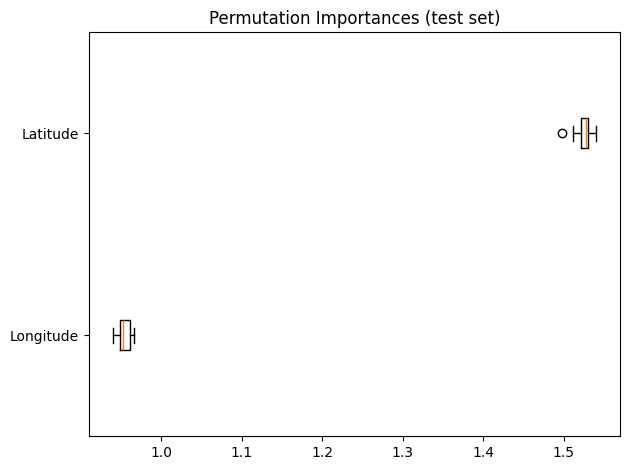

In [ ]:
# prompt: interpret the model for insights on the feature importance

import pandas as pd
import matplotlib.pyplot as plt
# Assuming 'X' is your feature matrix and 'models' is your dictionary of trained models.
# You'll need to adapt this based on the specific model you choose to interpret.

importances = {}

# Example: Get feature importances from a RandomForestRegressor
model = models['Random Forest']  # Or whichever model you want to analyze
if isinstance(model, RandomForestRegressor):
    model.fit(X,y)
    importances = model.feature_importances_
    feature_names = X.columns
    feature_importance_df = pd.DataFrame({'feature':feature_names, 'importance': importances})
    print(feature_importance_df.sort_values('importance', ascending=False))

# Example using permutation importance for any model:
from sklearn.inspection import permutation_importance
result = permutation_importance(model, X, y, n_repeats=10, random_state=42, n_jobs=2)
sorted_idx = result.importances_mean.argsort()

fig, ax = plt.subplots()
ax.boxplot(result.importances[sorted_idx].T, vert=False, labels=X.columns[sorted_idx])
ax.set_title("Permutation Importances (test set)")
fig.tight_layout()
plt.show()


#More detailed explanation of the feature importance scores based on the selected model.
# For tree-based models, higher values indicate stronger predictive power.
# For linear models, the coefficients show the effect of each feature on the target.
# If using permutation importance, the ranking reflects how much the model's accuracy decreases when the feature is randomly shuffled.


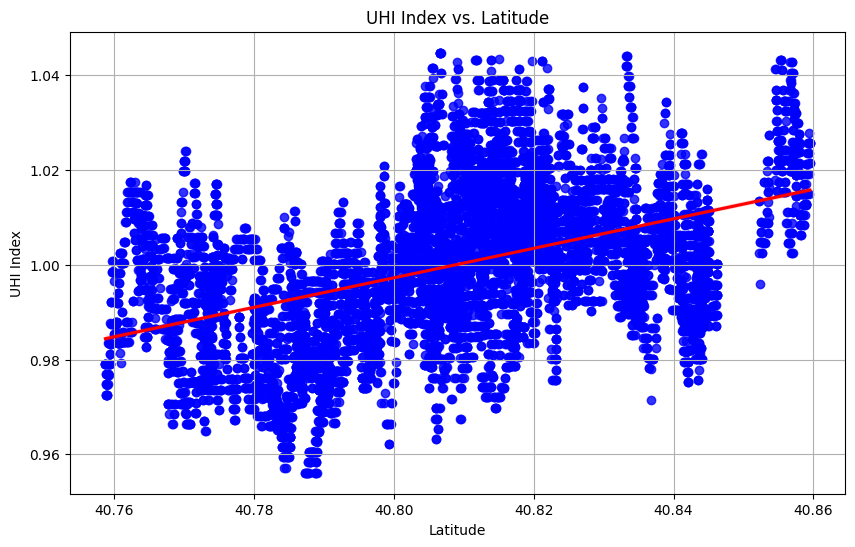

In [ ]:
import matplotlib.pyplot as plt
# Assuming 'grouped_df' is your DataFrame with 'Latitude' and 'UHI Index' columns
plt.figure(figsize=(10, 6))
sns.regplot(x='Latitude', y='UHI Index', data=grouped_df, scatter_kws={"color": "blue"}, line_kws={"color": "red"})
plt.xlabel('Latitude')
plt.ylabel('UHI Index')
plt.title('UHI Index vs. Latitude')
plt.grid(True)
plt.show()


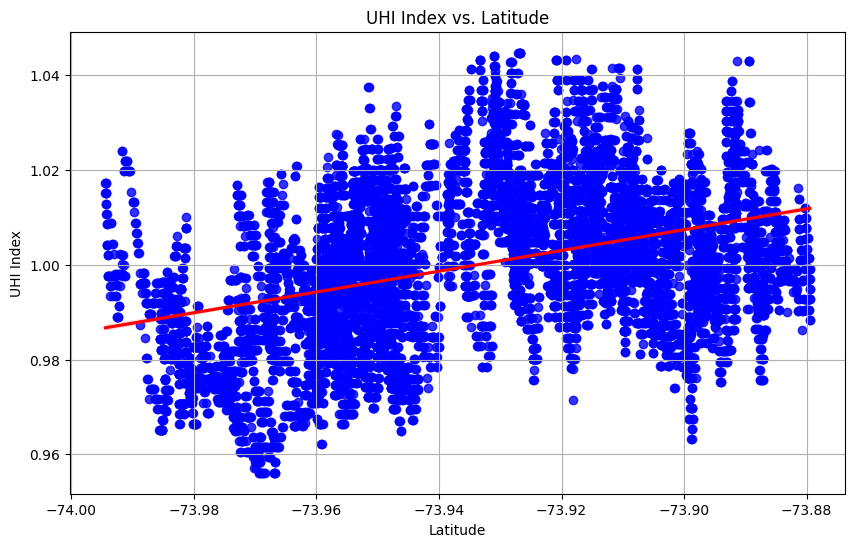

In [ ]:
import matplotlib.pyplot as plt
# Assuming 'grouped_df' is your DataFrame with 'Latitude' and 'UHI Index' columns
plt.figure(figsize=(10, 6))
sns.regplot(x='Longitude', y='UHI Index', data=grouped_df, scatter_kws={"color": "blue"}, line_kws={"color": "red"})
plt.xlabel('Latitude')
plt.ylabel('UHI Index')
plt.title('UHI Index vs. Latitude')
plt.grid(True)
plt.show()


# Submission

In [ ]:
# prompt: retrain the best performing model on all the data (without cross-fold validation)

# Assuming 'X' and 'y' are your features and target variable from the grouped_df
# and 'sorted_results' contains the cross-validation results.

# Retrain the best performing model on the entire dataset
best_model_name = list(sorted_results.keys())[1] # Get the name of the best model
best_model = models[best_model_name]

best_model.fit(X, y) # Fit on the entire dataset

# Now 'best_model' is trained on all the data and ready for predictions on new data.
# You can save this model for later use if needed.
import joblib
joblib.dump(best_model, f'{best_model_name}_final_model.pkl')


['Random Forest_final_model.pkl']

In [ ]:
# prompt: use the model to predict X and use y as y_true and report the r2

from sklearn.metrics import r2_score

# Assuming 'best_model' is already trained and 'X' contains the features for prediction
# and 'y' is your true target values

y_pred = best_model.predict(X)
r2 = r2_score(y, y_pred)
print(f"R-squared score on the entire dataset: {r2}")


R-squared score on the entire dataset: 0.9963436861581668


In [ ]:
# prompt: load submission.csv and use the model to predict the UHI_Index

import pandas as pd
# Load the submission data
submission_df = pd.read_csv("submission.csv")

submission_X = submission_df.drop('UHI Index', axis=1)

# Choose the best-performing model from cross-validation results
best_model_name = 'Random Forest'  # Replace with the actual best model
best_model = models[best_model_name]

# Retrain the best model on the entire training dataset (grouped_df)
best_model.fit(X, y)


# Make predictions on the submission data
submission_predictions = best_model.predict(submission_X)

# Create a new DataFrame for submission
submission_results = submission_X
submission_results['UHI_Index'] = submission_predictions

# Save the predictions to a CSV file
submission_results.to_csv('submission_predictions.csv', index=False)
